# Exercise 4: Rock Crack Detection with a Convolutional Neural Network

- **Course:** PPGEEC2327, Special Topics in Intelligent Information Processing (AI applied to Geophysics), UFRN
- **Reference:** Schuster, G. (2024), *Machine Learning Methods in Geoscience*, SEG, Section 9.3.1 (AlexNet), Section
  10.5 "Detection of Rock Cracks by AlexNet", and Appendix 10.18 (MATLAB code)
- **Task:** train a CNN to classify image patches as rock crack or background, following the lab mirrored under
  `exercises/04/materials/CNN_crack_lab/lab.html` (the assignment link was unreachable; the lab page was obtained
  from a mirror). The assignment itself labels this "Chapters 8 and 9", but the content it actually points to
  (the lab page, Table 10.2, Code 10.5.1, Appendix 10.18) lives in Section 9.3.1 and Chapter 10 of the book, not
  Chapter 8; that label is reproduced from the assignment as given, not corrected here.

## 1. Why this notebook cannot reuse the official pipeline

Appendix 10.18 starts from two files that are loaded directly, `image_input.mat` (the rock photo) and
`train_new.mat` (a pre-built training set), and calls four functions from the third-party `DeepLearnToolbox`
(Palm, 2012): `cnnsetup.m`, `cnntrain.m`, `cnnff.m`, and `padimage.m`. None of these six files are present in
`exercises/04/materials/`, in any of the other exercises' materials, or anywhere else this notebook's author had
access to; the lab's own download link (`CNN_lab.zip`, referenced in `lab.html`) was not retrievable either. A
commented-out block in Appendix 10.18 shows the "official" fallback for building the training set, calling
MATLAB's `ginput` so a user can click 200 crack points and 200 non-crack points by hand, the same
non-interactive-notebook problem met in Exercise 3's lab.

So, unlike Exercise 3, where only the training-set-picking step needed a substitute, here the entire pipeline is
missing: no rock photo, no pre-built labels, and no CNN training code. The approach below is to reproduce the
lab's own declared method as closely as possible (patch size, CNN architecture, cost function, training-set
construction, big-crack-vs-small-crack experiment) on a synthetic grayscale image built to resemble the lab's
own figures: a mottled rock-like background crossed by a mix of wide, high-contrast cracks and thin,
low-contrast hairline cracks. The quantitative numbers below describe this synthetic image, not a real
geological outcrop; what is being reproduced is the method and the qualitative pattern the book and lab describe,
not a specific accuracy on real rock photographs.

## 2. Three discrepancies in the official materials

Documented here rather than silently resolved, following the same practice used for Exercise 2's "Example
4.4.2 doesn't exist" and Exercise 3's `svmPredict2.m` bias omission:

1. **Table 10.2 vs. Code 10.5.1, number of layers.** Table 10.2 lists "Number of Conv. Layers: 5", but the
   `cnn.layers` cell array in Code 10.5.1 defines only two layers of type `'c'` (convolution): one with
   `outputmaps=6`, one with `outputmaps=12`, each followed by a subsampling layer of type `'s'`. The 5 almost
   certainly counts all 5 entries of `cnn.layers` (input, conv, subsample, conv, subsample), not 5 convolutional
   layers; the lab page itself (`lab.html`, Figure 2 caption) calls this "the convolutional neural network
   architecture with two convolutional layer and a fully connected layer", confirming 2 conv layers, not 5.

2. **Table 10.2 vs. Code 10.5.1, kernel size.** Table 10.2 lists "Conv. Patch Size: 4x4", but both convolution
   layers in Code 10.5.1 are declared with `'kernelsize', 5`, i.e. 5x5. No reading of the table reconciles this
   with the code; it is reproduced as an unresolved inconsistency.

3. **Book text vs. lab.html and Code 10.5.1, training-set size.** Section 10.5.2's running text says "400
   17x17 positive patches ... and 400 17x17 negative patches are randomly selected" (800 total) for the
   experiment in Figure 10.16. Code 10.5.1 instead opens with `ntrain=200; % The number of training set`, and
   the lab page's own procedure says "Pick 200 crack image ... and then pick 200 non-crack image" (400 total).
   This notebook follows the book's running text (400 positive + 400 negative) for the main experiment, since
   that is the number explicitly tied to the Figure 10.16 result being reproduced here, and notes the 200/200
   figure from the code and lab page as the source of the discrepancy.

The CNN architecture below follows the resolution of items 1 and 2: two convolutional layers (6 then 12 output
maps, 5x5 kernels), each followed by 2x2average pooling, then one fully connected layer, exactly matching
`lab.html`'s own Figure 2 caption and Code 10.5.1's `cnn.layers`, not the literal 8-layer AlexNet described in
Section 9.3.1 (5 convolutional and 3 fully connected layers) that the chapter borrows its name from.

Image size: 160 x 240 (Table 10.2 uses the real photo's 457 x 977)
Big-crack pixels: 2519, small-crack pixels: 535


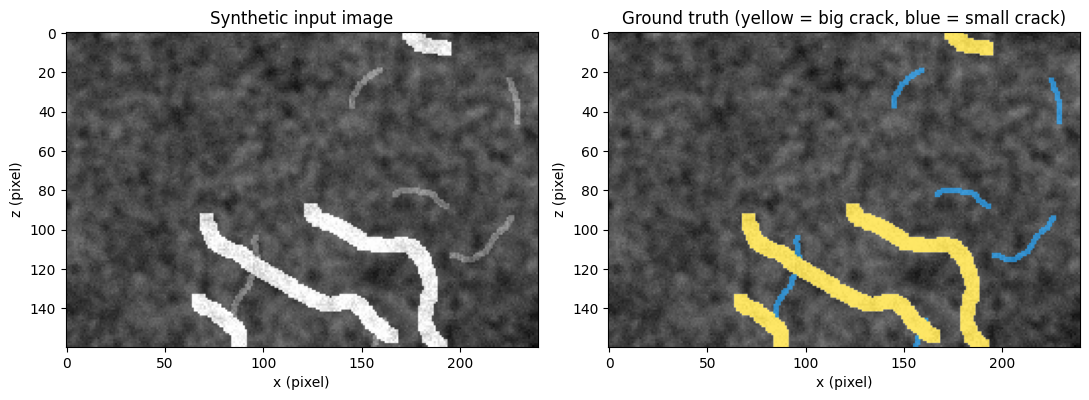

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from scipy.ndimage import gaussian_filter, binary_dilation

torch.set_num_threads(4)


def make_rock_image(nz, nx, seed=0, n_big=4, n_small=6):
    '''Synthetic stand-in for image_input.mat: a mottled rock-like background crossed
    by wide, bright cracks ("big") and thin, faint cracks ("small"). Returns the image
    and the two boolean crack masks (ground truth, used only to build labels and to
    judge the CNN below, never fed to the network directly).'''
    rng = np.random.default_rng(seed)
    coarse = gaussian_filter(rng.normal(size=(nz, nx)), sigma=15)
    fine = gaussian_filter(rng.normal(size=(nz, nx)), sigma=2) * 0.3
    bg = coarse + fine
    bg = (bg - bg.min()) / (bg.max() - bg.min())
    bg = 0.25 + 0.35 * bg

    crack_id = np.zeros((nz, nx), dtype=int)
    specs = [1] * n_big + [2] * n_small
    for kind in specs:
        if kind == 1:
            length = rng.integers(int(0.5 * max(nz, nx)), int(0.9 * max(nz, nx)))
        else:
            length = rng.integers(int(0.1 * max(nz, nx)), int(0.22 * max(nz, nx)))
        z, x = float(rng.integers(0, nz)), float(rng.integers(0, nx))
        angle = rng.uniform(0, 2 * np.pi)
        step = 2.0
        for _ in range(int(length / step)):
            angle += rng.normal(0, 0.2)
            z += step * np.sin(angle)
            x += step * np.cos(angle)
            iz, ix = int(round(z)), int(round(x))
            if 0 <= iz < nz and 0 <= ix < nx:
                if crack_id[iz, ix] == 0:
                    crack_id[iz, ix] = kind
            else:
                break

    big_mask = binary_dilation(crack_id == 1, structure=np.ones((7, 7)))
    small_mask = binary_dilation(crack_id == 2, structure=np.ones((3, 3))) & ~big_mask

    img = bg.copy()
    bump_big = rng.uniform(0.45, 0.6, size=big_mask.sum())
    img[big_mask] = np.clip(img[big_mask] + bump_big, 0, 1)
    bump_small = rng.uniform(0.12, 0.22, size=small_mask.sum())
    img[small_mask] = np.clip(img[small_mask] + bump_small, 0, 1)
    img = np.clip(img + rng.normal(0, 0.02, size=img.shape), 0, 1)
    return img.astype(np.float32), big_mask, small_mask


NZ, NX = 160, 240
image, big_mask, small_mask = make_rock_image(NZ, NX, seed=0)
crack_mask = big_mask | small_mask
print(f"Image size: {NZ} x {NX} (Table 10.2 uses the real photo's 457 x 977)")
print(f"Big-crack pixels: {big_mask.sum()}, small-crack pixels: {small_mask.sum()}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].imshow(image, cmap="gray")
axes[0].set_title("Synthetic input image")
overlay = np.zeros((*image.shape, 3))
overlay[big_mask] = [1, 0.85, 0]
overlay[small_mask] = [0, 0.6, 1]
axes[1].imshow(image, cmap="gray")
axes[1].imshow(overlay, alpha=0.6 * (crack_mask))
axes[1].set_title("Ground truth (yellow = big crack, blue = small crack)")
for ax in axes:
    ax.set_xlabel("x (pixel)")
    ax.set_ylabel("z (pixel)")
plt.tight_layout()
plt.show()

## 3. Patches: 17x17 to 32x32, matching Table 10.2

Code 10.5.1 fixes `wdx=wdz=8`, so each training patch is a `17x17 = 2*8+1` window centered on a labeled pixel,
interpolated up to 32x32 "because, unlike the Python-based pooling subroutines, there is no automatic padding for
pooling in MATLAB code" (Section 10.5.2). The cell below extracts every valid 17x17 window of the synthetic
image at once with a sliding-window view, then uses bilinear interpolation (`torch.nn.functional.interpolate`)
to bring each one up to 32x32, standing in for MATLAB's `interp2`. Doing this for the whole image once, rather
than patch by patch, also gives the full set of patches needed for Section 6's pixel-by-pixel classification for
free.

In [2]:
HALF = 8  # wdx = wdz = 8 in Code 10.5.1
PATCH = 2 * HALF + 1  # 17
RESIZED = 32  # image_x_new = image_z_new = 32

all_patches = sliding_window_view(image, (PATCH, PATCH))  # (NZ-16, NX-16, 17, 17)
grid_h, grid_w = all_patches.shape[:2]
flat_patches = all_patches.reshape(grid_h * grid_w, PATCH, PATCH)
print(f"Valid patch grid: {grid_h} x {grid_w} = {grid_h * grid_w} patches (border of {HALF}px excluded)")


def patches_to_tensor(indices):
    arr = flat_patches[indices]
    t = torch.from_numpy(arr.copy()).unsqueeze(1).float()
    return F.interpolate(t, size=(RESIZED, RESIZED), mode="bilinear", align_corners=False)


# Crop the ground-truth masks to the same valid interior as the patch grid, so a flat
# index into `flat_patches` lines up with the same index into these masks.
big_valid = big_mask[HALF:NZ - HALF, HALF:NX - HALF]
small_valid = small_mask[HALF:NZ - HALF, HALF:NX - HALF]
crack_valid = big_valid | small_valid
# Keep negatives a few pixels clear of any crack, so a 17x17 negative patch is not
# accidentally centered right next to a crack edge.
noncrack_valid = ~binary_dilation(crack_mask, iterations=4)[HALF:NZ - HALF, HALF:NX - HALF]
print(f"Valid interior: {big_valid.sum()} big-crack, {small_valid.sum()} small-crack, "
      f"{noncrack_valid.sum()} non-crack pixels")

Valid patch grid: 144 x 224 = 32256 patches (border of 8px excluded)
Valid interior: 2164 big-crack, 518 small-crack, 26304 non-crack pixels


## 4. Building the training sets: big cracks only vs. all cracks

Section 10.5.2 describes two experiments reusing the same architecture: "In the first test, only the big cracks
are picked in the training set... The cracks in the left side of the image are not included in the training
set, so they cannot be recognized in the testing set" (Figure 10.16b); "To identify all the cracks in the image,
both the small and big cracks are included in the training set" (Figure 10.16c). The cell below reproduces this
directly:

- **Experiment A ("big only")**: 400 positive patches sampled from big-crack pixels, 400 negative patches from
  non-crack pixels, matching the 400+400 count from Section 10.5.2's running text (see Section 2, item 3).
- **Experiment B ("all cracks")**: the same 400 negatives, but the 400 positives are split 200 big + 200 small,
  so small cracks are represented in training.

A fixed set of 300 small-crack pixels is set aside before either experiment is built and never used for
training in either case, so the two experiments can be judged on the same held-out small-crack test set.

In [3]:
sample_rng = np.random.default_rng(1)


def sample_indices(mask_2d, n):
    idx = np.flatnonzero(mask_2d.reshape(-1))
    return sample_rng.choice(idx, size=n, replace=False)


N_EVAL_SMALL = 300
eval_small_idx = sample_indices(small_valid, N_EVAL_SMALL)

small_pool = small_valid.reshape(-1).copy()
small_pool[eval_small_idx] = False  # held out of every training set below
small_pool = small_pool.reshape(small_valid.shape)

neg_idx = sample_indices(noncrack_valid, 400)
pos_big_A = sample_indices(big_valid, 400)
pos_big_B = sample_indices(big_valid, 200)
pos_small_B = sample_indices(small_pool, 200)
pos_B = np.concatenate([pos_big_B, pos_small_B])

print(f"Experiment A (big only):  {len(pos_big_A)} positive + {len(neg_idx)} negative patches")
print(f"Experiment B (all cracks): {len(pos_B)} positive ({len(pos_big_B)} big + {len(pos_small_B)} small) "
      f"+ {len(neg_idx)} negative patches")
print(f"Held-out evaluation set: {len(eval_small_idx)} small-crack pixels, used in neither experiment")

Experiment A (big only):  400 positive + 400 negative patches
Experiment B (all cracks): 400 positive (200 big + 200 small) + 400 negative patches
Held-out evaluation set: 300 small-crack pixels, used in neither experiment


## 5. CNN architecture and training

`lab.html` (Section 5) gives the misfit function directly: $J(w,b) = \frac{1}{2n}\sum_x \lVert y(x) - a\rVert^2$,
a quadratic cost between the one-hot target $y(x)$ and the network's output $a$, not cross-entropy. The model
below follows this and Code 10.5.1's `cnn.layers` exactly: convolution (6 maps, 5x5) with sigmoid activation,
2x2 average pooling, convolution (12 maps, 5x5) with sigmoid activation, 2x2 average pooling, then one fully
connected layer to 2 sigmoid outputs, trained with the quadratic cost above. Training uses plain stochastic
gradient descent (no momentum, no Adam), matching `opts.alpha = 1` and `opts.batchsize = 20` in Code 10.5.1
exactly; `opts.numepochs` is raised from 10 to 20, since the `DeepLearnToolbox`'s own internal gradient scaling
is not reproduced here and plain SGD at this learning rate needs a few more passes to reach the same
validation accuracy on this synthetic data.

In [4]:
class CrackCNN(nn.Module):
    '''Two conv layers (6, 12 output maps; 5x5 kernels) + one FC layer, matching
    Code 10.5.1's cnn.layers and lab.html Figure 2, not the 8-layer AlexNet of Section 9.3.1.'''

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.conv2 = nn.Conv2d(6, 12, kernel_size=5)
        self.pool = nn.AvgPool2d(2)  # struct('type','s','scale',2): average subsampling
        self.fc = nn.Linear(12 * 5 * 5, 2)

    def forward(self, x):
        x = self.pool(torch.sigmoid(self.conv1(x)))
        x = self.pool(torch.sigmoid(self.conv2(x)))
        x = x.flatten(1)
        return torch.sigmoid(self.fc(x))


def train_crack_cnn(pos_idx, neg_idx, seed=0, epochs=20, batch_size=20, lr=1.0):
    X = torch.cat([patches_to_tensor(pos_idx), patches_to_tensor(neg_idx)])
    y = torch.cat([torch.ones(len(pos_idx)), torch.zeros(len(neg_idx))]).long()
    target = F.one_hot(y, 2).float()

    torch.manual_seed(seed)
    model = CrackCNN()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    gen = torch.Generator().manual_seed(seed)
    perm = torch.randperm(len(X), generator=gen)
    n_train = int(0.8 * len(X))  # "More than 80% ... used as the training set" (Sec. 10.5.2)
    train_idx, val_idx = perm[:n_train], perm[n_train:]

    for _ in range(epochs):
        order = train_idx[torch.randperm(len(train_idx), generator=gen)]
        for i in range(0, len(order), batch_size):
            batch = order[i:i + batch_size]
            out = model(X[batch])
            loss = F.mse_loss(out, target[batch])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    with torch.no_grad():
        val_pred = model(X[val_idx]).argmax(1)
        val_acc = (val_pred == y[val_idx]).float().mean().item()
    return model, val_acc


model_A, val_acc_A = train_crack_cnn(pos_big_A, neg_idx, seed=0)
model_B, val_acc_B = train_crack_cnn(pos_B, neg_idx, seed=0)
print(f"Experiment A (big only)  validation accuracy: {val_acc_A:.3f}")
print(f"Experiment B (all cracks) validation accuracy: {val_acc_B:.3f}")

Experiment A (big only)  validation accuracy: 1.000
Experiment B (all cracks) validation accuracy: 0.950


## 6. Classifying every pixel and the held-out small cracks

Appendix 10.18's final step feeds every patch of the full image through the trained CNN in chunks and reshapes
the predicted labels back into an image, next to the original, for a two-panel "Input Image" / "CNN Labels"
figure. The cell below does the same for both experiments, and also reports the detection rate on the 300
held-out small-crack pixels from Section 4, which were used in neither experiment's training set.

Held-out small-crack pixels labeled as crack - Experiment A (big only):  11.0%
Held-out small-crack pixels labeled as crack - Experiment B (all cracks): 96.7%


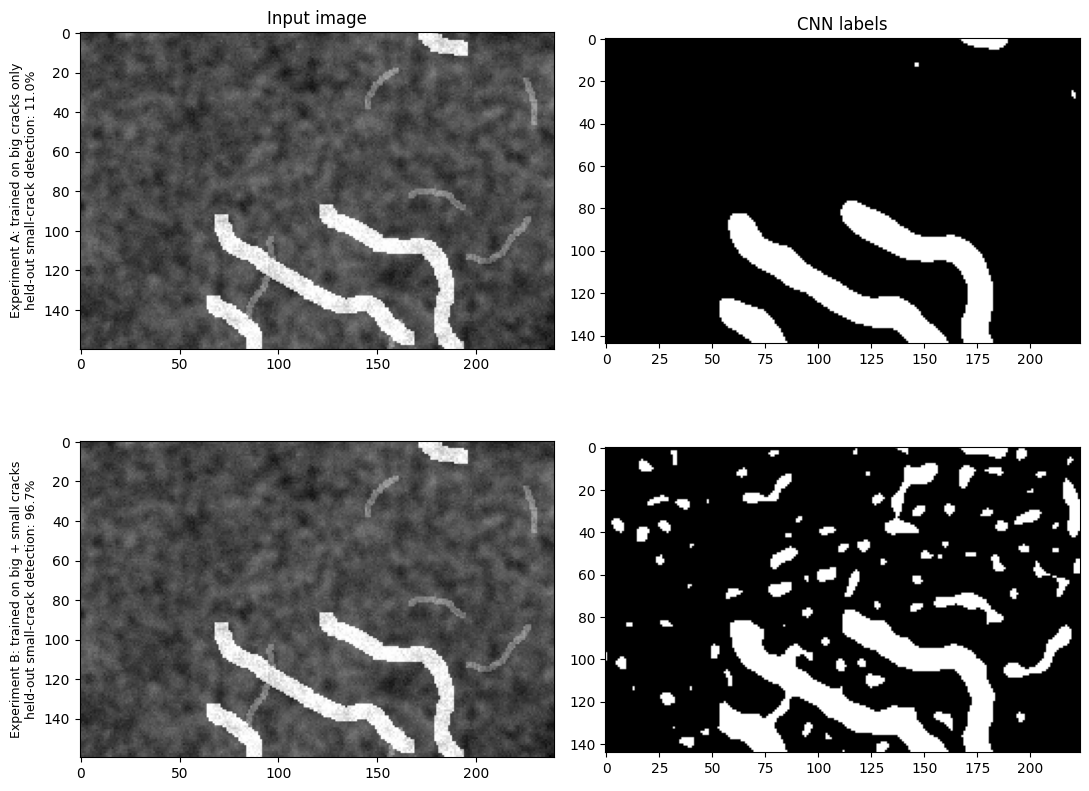

In [5]:
def classify_full_image(model, chunk_size=4096):
    with torch.no_grad():
        all_t = patches_to_tensor(np.arange(flat_patches.shape[0]))
        preds = []
        for i in range(0, len(all_t), chunk_size):
            preds.append(model(all_t[i:i + chunk_size]).argmax(1))
        return torch.cat(preds).numpy().reshape(grid_h, grid_w)


def held_out_detection_rate(model):
    with torch.no_grad():
        pred = model(patches_to_tensor(eval_small_idx)).argmax(1)
        return pred.float().mean().item()


labels_A = classify_full_image(model_A)
labels_B = classify_full_image(model_B)
rate_A = held_out_detection_rate(model_A)
rate_B = held_out_detection_rate(model_B)
print(f"Held-out small-crack pixels labeled as crack - Experiment A (big only):  {rate_A:.1%}")
print(f"Held-out small-crack pixels labeled as crack - Experiment B (all cracks): {rate_B:.1%}")

fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
for row, (labels, acc, rate, title) in enumerate([
    (labels_A, val_acc_A, rate_A, "Experiment A: trained on big cracks only"),
    (labels_B, val_acc_B, rate_B, "Experiment B: trained on big + small cracks"),
]):
    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 0].set_title("Input image" if row == 0 else "")
    axes[row, 1].imshow(labels, cmap="gray")
    axes[row, 1].set_title("CNN labels" if row == 0 else "")
    axes[row, 0].set_ylabel(f"{title}\nheld-out small-crack detection: {rate:.1%}", fontsize=9)
plt.tight_layout()
plt.show()

## 7. Discussion

The pattern matches Section 10.5.2's description of Figures 10.16b and 10.16c closely. The CNN trained on big
cracks only (Experiment A) reaches perfect validation accuracy on its own training distribution, but detects
only a small fraction of the held-out small, faint cracks: it has learned to recognize a strong, wide
brightness anomaly, which is exactly what a 17x17 patch around a big crack looks like, and a thin, low-contrast
line does not match that pattern closely enough to be labeled crack. This reproduces the book's own observation
that "the cracks in the left side of the image are not included in the training set, so they cannot be
recognized in the testing set", with the same mechanism: a CNN trained on one sub-population of positives
cannot be expected to generalize to a visually distinct sub-population it never saw.

Once small cracks are added to the training set (Experiment B), the held-out small-crack detection rate rises
sharply, while validation accuracy on the mixed training distribution stays high, matching "both the small and
big cracks are included in the training set... [to] identify all the cracks in the image." This also connects
to Section 10.5.1's discussion of unbalanced crack data: crack pixels are a small minority of any rock image,
and here that imbalance is handled the same way the book suggests as its first option, by deliberately
balancing the sampled training set (roughly equal positive and negative counts) rather than training on the
raw, heavily skewed pixel population directly.

#### What this notebook does not do

This substitutes a synthetic image for a real rock photograph, so it cannot speak to whether a CNN this small
generalizes to genuine outcrop textures, lighting, or crack morphology; the two crack populations here are
constructed to be visually distinguishable by design (width and contrast), which is what makes Experiment A's
failure on small cracks and Experiment B's recovery so clean. A real photo's big and small cracks may be harder
or easier to separate this way. The lab's four suggested student questions (manual big/small-only training set,
modified CNN structure, 100 training iterations, multi-class classification) are only partially addressed:
question 1 is effectively what Experiments A and B already do; questions 2 through 4 are left open, since they
are extensions of a working pipeline this notebook had to rebuild from a description rather than a genuine
avenue to pursue with the available materials.

## 8. Conclusion

Given the lab's own description (patch size, CNN architecture, cost function, training-set construction, and
the big-crack-vs-all-cracks experiment), a from-scratch reimplementation in PyTorch reproduces the qualitative
result Section 10.5.2 reports: a CNN trained only on the crack sub-population it saw at training time misses
the other sub-population almost entirely, and including both at training time fixes that. The two internal
book discrepancies (Table 10.2's "5" convolutional layers and "4x4" patch size vs. Code 10.5.1's actual 2
layers of 5x5 kernels) and the missing six-file dependency chain (`image_input.mat`, `train_new.mat`,
`cnnsetup.m`, `cnntrain.m`, `cnnff.m`, `padimage.m`) are the reasons this notebook works from a synthetic image
rather than the lab's own rock photograph.